# Lab 5-C（06）：Harness——用 deepagents 組一個值班 agent

**目標**：用 `deepagents` 的 `create_deep_agent` 一次組好 harness：工具、ops-runbook skill、AGENTS.md 記憶、
唯讀的 log-checker 子 agent、重啟前的人工審批。過程中打開框架看它內部的 messages 與工具呼叫，把 harness 的每一塊對到實際行為。

**你會學到**
- `create_deep_agent` 的參數各對應 harness 的哪一塊
- 框架預設的 prompt 對 3B 小模型太大時，怎麼用正式的擴充點瘦身
- 從 trace 看見 skills 按需載入、子 agent 隔離 context、`interrupt_on` 審批

**前置**：Lab 5-B（05）；先讀 `00_concepts.md` 第 6、7 節（harness 的組成、什麼時候切多個 agent）。

**對應投影片**：「Harness 是什麼」「子 agent 隔離 context」「Deep Agents 長任務」「通用 Agent 加 Skills」「什麼時候切多個 agent」「Lab5-C Harness agent」

![Harness 分層架構圖](images/harness.jpg)

*圖：由上而下分層：你的程式下指令，先經過權限與審批；核心是一個模型＋迴圈，旁邊掛 skills（按需載入）和子 agent（只回摘要）；往下呼叫工具；最底層是檔案記憶與舊對話壓縮。*

## Step 1：準備工作目錄

`oncall/` 是 agent 的家目錄：一份 `AGENTS.md`（值班慣例）和 `skills/` 底下兩個 skill。
deepagents 的檔案工具可以寫檔，所以每次複製一份到 `workspace/`（已列入 `.gitignore`），不動原始檔。

In [1]:
import shutil
from pathlib import Path

WS = Path("workspace")
shutil.rmtree(WS, ignore_errors=True)
shutil.copytree("oncall", WS)
for p in sorted(WS.rglob("*")):
    if p.is_file():
        print(f"{str(p):<45} {p.stat().st_size:>4} bytes")
print()
print((WS / "skills/ops-runbook/SKILL.md").read_text(encoding="utf-8"))

workspace/AGENTS.md                            244 bytes
workspace/skills/incident-report/SKILL.md      406 bytes
workspace/skills/ops-runbook/SKILL.md          574 bytes

---
name: ops-runbook
description: 線上事故（502、逾時、連線池用盡）的排查步驟。使用者回報服務出錯時使用。
---

# ops-runbook：線上事故排查

1. 用 read_logs(level="ERROR") 看最近的錯誤，找出最下游、最先出錯的服務。
2. 用 query_metrics 查那個服務的 error_rate；order-db-proxy 另外查 pool_used。
3. pool_used 到 50 代表連線池用盡：根因是 order-db-proxy，短期處理是重啟它。
4. 重啟前先說明證據，等人核准；重啟後再查一次 error_rate，低於 1% 才算恢復。



skill 的開頭（`---` 之間）是 frontmatter：`name` 和 `description`。harness 只把這兩行放進 system prompt，
模型判斷用得到時才去讀全文——這就是 progressive disclosure。

## Step 2：工具、模型、子 agent

工具用 `@tool`＋Pydantic 參數。子 agent 是一個 dict：名稱、說明（主 agent 看到的說明書）、自己的 prompt、**只有唯讀工具**。

In [2]:
import os

from langchain_core.tools import tool
from langchain_openai import ChatOpenAI

import oncall_tools as ot
from course_utils.llm import primary_endpoint

ot.reset_env()


@tool(args_schema=ot.ReadLogsArgs)
def read_logs(service=None, level=None, keyword=None, limit=8) -> str:
    """讀應用程式日誌，可依服務、等級、關鍵字過濾。"""
    return ot.read_logs(service, level, keyword, limit)


@tool(args_schema=ot.QueryMetricsArgs)
def query_metrics(service, metric="error_rate") -> str:
    """查某個服務的監控指標（error_rate、p95_latency_ms、pool_used）。"""
    return ot.query_metrics(service, metric)


@tool(args_schema=ot.RestartArgs)
def restart_service(service) -> str:
    """重啟一個服務（寫入動作）。"""
    return ot.restart_service(service)


ep = primary_endpoint()  # 有 CLOUD_API_KEY 走雲端，否則本機 Ollama
model = ChatOpenAI(base_url=ep.base_url, api_key=ep.api_key, model=ep.model, temperature=0)

log_checker = {
    "name": "log-checker",
    "description": "查一個懷疑的原因：讀日誌、查指標、回報證據",
    "system_prompt": "你是唯讀的查證員，只能讀不能改。用工具查完後，用繁體中文回三行：結論、證據、信心。",
    "tools": [read_logs, query_metrics],
}

## Step 3：照投影片組裝

| harness 的一塊 | `create_deep_agent` 參數 |
|---|---|
| 角色 | `system_prompt=` |
| 工具 | `tools=`（另外自動加上檔案工具與 `task`） |
| 檔案記憶 | `memory=["/AGENTS.md"]` |
| skills | `skills=["/skills/"]`（模型用內建 `read_file` 讀 SKILL.md） |
| 子 agent | `subagents=[...]`，用內建的 `task` 工具呼叫 |
| 權限與審批 | `interrupt_on={"restart_service": True}`＋`checkpointer` |
| 工作目錄 | `backend=FilesystemBackend(root_dir=...)` |

In [3]:
from deepagents import create_deep_agent
from deepagents.backends import FilesystemBackend
from langgraph.checkpoint.memory import InMemorySaver

agent = create_deep_agent(
    model,
    tools=[read_logs, query_metrics, restart_service],
    system_prompt="你是晨光外送的值班 agent。用繁體中文回答。",
    backend=FilesystemBackend(root_dir=str(WS)),
    skills=["/skills/"],
    memory=["/AGENTS.md"],
    subagents=[log_checker],
    interrupt_on={"restart_service": True},
    checkpointer=InMemorySaver(),
)

點一下：`create_deep_agent` 回傳的是一張 LangGraph 圖。列出它的節點，harness 的外掛（middleware）都在裡面——
記憶、skills、子 agent、壓縮（Summarization）、審批（HumanInTheLoop）各佔一格，中間是 `model` 和 `tools` 這個迴圈。

In [4]:
for name in agent.get_graph().nodes:
    print(" ", name)

  __start__
  model
  tools
  _ParentNotifierMiddleware.after_agent
  PatchToolCallsMiddleware.before_agent
  SkillsMiddleware.before_agent
  SkillsMiddleware.before_model
  MemoryMiddleware.before_agent
  HumanInTheLoopMiddleware.after_model
  __end__


## Step 4：先看它壞掉——框架的 prompt 比 3B 的 context 還大

用一個 callback 偷看每次送給模型的內容：system prompt、對話、工具說明各有多大。

In [5]:
import json

from langchain_core.callbacks import BaseCallbackHandler
from langgraph.errors import GraphRecursionError


class RequestSpy(BaseCallbackHandler):
    def __init__(self):
        self.records = []

    def on_chat_model_start(self, serialized, messages, **kwargs):
        tools = kwargs.get("invocation_params", {}).get("tools", [])
        first = messages[0][0] if messages and messages[0] else None
        system = first.content if first is not None and first.type == "system" else ""
        if not isinstance(system, str):
            system = "".join(b.get("text", "") for b in system if isinstance(b, dict))
        self.records.append({"system": system,
                             "prompt_chars": sum(len(str(m.content)) for m in messages[0]),
                             "tool_chars": len(json.dumps(tools, ensure_ascii=False)),
                             "tools": [t["function"]["name"] for t in tools]})


spy = RequestSpy()
cfg_default = {"configurable": {"thread_id": "default-1"}, "recursion_limit": 12, "callbacks": [spy]}
try:
    out = agent.invoke({"messages": [("user", "order-db-proxy 的 error_rate 現在多少？")]}, cfg_default)
    print("最後回覆：", repr(out["messages"][-1].content[:200]))
except GraphRecursionError:
    print("跑了 12 步還停不下來：GraphRecursionError")
r = spy.records[0]
print(f"第一次請求：system＋對話 {r['prompt_chars']} 字，工具說明 {r['tool_chars']} 字")
print("模型看到的工具：", r["tools"])
for m in agent.get_state(cfg_default).values["messages"][1:6]:
    calls = getattr(m, "tool_calls", None)
    print(" ", type(m).__name__, calls[0]["name"] + str(calls[0]["args"]) if calls else repr(str(m.content)[:80]))

跑了 12 步還停不下來：GraphRecursionError
第一次請求：system＋對話 7623 字，工具說明 12106 字
模型看到的工具： ['ls', 'read_file', 'write_file', 'edit_file', 'delete', 'glob', 'grep', 'task', 'read_logs', 'query_metrics', 'restart_service']
  AIMessage query_metrics{'service': 'order-db-proxy', 'metric': 'error_rate'}
  ToolMessage 'order-db-proxy error_rate 最近：14:00=3.0, 14:05=12.0, 14:10=15.5, 14:15=16.0, 14:2'
  AIMessage query_metrics{'metric': 'error_rate', 'service': 'order-db-proxy'}
  ToolMessage 'order-db-proxy error_rate 最近：14:00=3.0, 14:05=12.0, 14:10=15.5, 14:15=16.0, 14:2'


兩萬字左右的請求，換成 token 已經超過這台 Ollama 的 context（`ollama ps` 顯示 4096）。
Ollama 遇到放不下的 prompt 會從前面截斷，模型看到的是殘缺的 system prompt：可能回空白、答非所問，
或像上面這樣反覆呼叫同一個工具停不下來，直到 `recursion_limit` 這條保險絲燒斷。

多出來的是：一整套檔案工具（`ls`、`write_file`、`edit_file`、`glob`、`grep`…）的長說明，以及 skills、memory 各自附帶的一大段英文使用指南。
對雲端大模型這是好事，對 3B 太重了。

## Step 5：替小模型瘦身

deepagents 有兩個正式的調整點，不用改套件原始碼：
1. **HarnessProfile**（依模型註冊）：拿掉用不到的內建工具、改短工具說明、關掉預設的 general-purpose 子 agent。
2. **同名 middleware 取代**：傳入自己的 `MemoryMiddleware`、`SkillsMiddleware`，給它們短的 prompt 模板。

In [6]:
from deepagents import GeneralPurposeSubagentProfile, HarnessProfile, MemoryMiddleware, register_harness_profile
from deepagents.middleware.skills import SkillsMiddleware

register_harness_profile("openai:qwen2.5:3b", HarnessProfile(
    excluded_tools=frozenset({"ls", "write_file", "edit_file", "delete", "glob", "grep", "write_todos"}),
    tool_description_overrides={
        "read_file": "讀一個檔案。file_path 用絕對路徑，例如 /skills/ops-runbook/SKILL.md。",
        "task": "派一個子 agent 去做獨立的查證，只拿回它的最後摘要。可用的子 agent：\n{available_agents}",
    },
    general_purpose_subagent=GeneralPurposeSubagentProfile(enabled=False),
))

backend = FilesystemBackend(root_dir=str(WS))
slim_agent = create_deep_agent(
    model,
    tools=[read_logs, query_metrics, restart_service],
    system_prompt="你是晨光外送的值班 agent。用繁體中文回答。",
    backend=backend,
    skills=["/skills/"],
    memory=["/AGENTS.md"],
    subagents=[log_checker],
    interrupt_on={"restart_service": True},
    checkpointer=InMemorySaver(),
    middleware=[
        MemoryMiddleware(backend=backend, sources=["/AGENTS.md"], system_prompt="## 值班記憶（AGENTS.md）\n{agent_memory}"),
        SkillsMiddleware(backend=backend, sources=["/skills/"],
                         system_prompt="## Skills\n{skills_locations}\n{skills_list}\n{skills_load_warnings}\n"
                                       "要用某個 skill 時，先用 read_file 讀它的 SKILL.md。"),
    ],
)

spy_slim = RequestSpy()
cfg = {"configurable": {"thread_id": "oncall-1"}, "recursion_limit": 25, "callbacks": [spy_slim]}
out = slim_agent.invoke({"messages": [("user", "order-db-proxy 的 error_rate 現在多少？")]}, cfg)
print("模型看到的工具：", spy_slim.records[0]["tools"])
print("回覆：", out["messages"][-1].content)

模型看到的工具： ['read_file', 'task', 'read_logs', 'query_metrics', 'restart_service']
回覆： order-db-proxy 的 error_rate 現在為 15.8%。


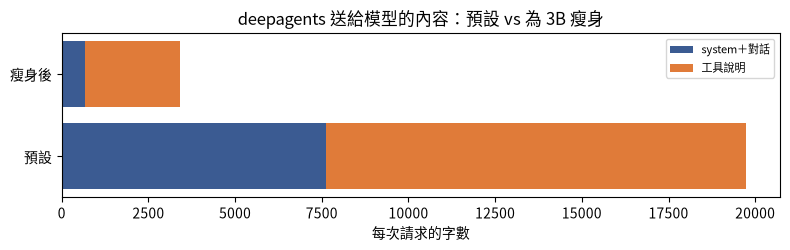

In [7]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()

before, after = spy.records[0], spy_slim.records[0]
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.barh(["預設", "瘦身後"], [before["prompt_chars"], after["prompt_chars"]], label="system＋對話", color="#3b5b92")
ax.barh(["預設", "瘦身後"], [before["tool_chars"], after["tool_chars"]],
        left=[before["prompt_chars"], after["prompt_chars"]], label="工具說明", color="#e07b39")
ax.set_xlabel("每次請求的字數")
ax.set_title("deepagents 送給模型的內容：預設 vs 為 3B 瘦身")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Step 6：點一下——harness 幫你組的 system prompt

把瘦身後真正送出去的 system prompt 印出來。你寫的只有第一行；後面兩段是 harness 組的：
- **值班記憶**：`AGENTS.md` 的全文，每次啟動都讀進來。
- **Skills**：只有名稱、說明和路徑，沒有步驟全文。

In [8]:
print(spy_slim.records[0]["system"])

你是晨光外送的值班 agent。用繁體中文回答。

## Skills
**Skills Skills**: `/skills/` (higher priority)
- **incident-report**: 事故結束後寫事故報告。使用者要求寫報告、寫 postmortem 時使用。
  -> Read `/skills/incident-report/SKILL.md` for full instructions
- **ops-runbook**: 線上事故（502、逾時、連線池用盡）的排查步驟。使用者回報服務出錯時使用。
  -> Read `/skills/ops-runbook/SKILL.md` for full instructions

要用某個 skill 時，先用 read_file 讀它的 SKILL.md。

## 值班記憶（AGENTS.md）
/AGENTS.md

# 值班慣例（晨光外送）

- 一律用繁體中文回答，先講結論，再列證據。
- 只有 order-db-proxy 和 notification 可以重啟，重啟前一定要人核准。
- 不要重啟 payment-api：會中斷進行中的付款。


## Step 7：skills 按需載入

接下來在同一個 thread 裡一次說一件事（3B 模型一次記不住整串流程）。第一件：讀 ops-runbook。
看 trace：模型呼叫 `read_file` 去讀 SKILL.md——全文到這時才進入 context。

In [9]:
def show_new(out: dict, start: int) -> None:
    for m in out["messages"][start:]:
        kind = type(m).__name__.replace("Message", "")
        if getattr(m, "tool_calls", None):
            print(f"  {kind:<6} → " + ", ".join(f"{c['name']}({json.dumps(c['args'], ensure_ascii=False)})" for c in m.tool_calls))
        elif m.content:
            print(f"  {kind:<6} ← {str(m.content)[:160]!r}")


def say(text: str) -> dict:
    start = len(slim_agent.get_state(cfg).values.get("messages", []))
    print(f"使用者：{text}")
    out = slim_agent.invoke({"messages": [("user", text)]}, cfg)
    show_new(out, start + 1)
    return out


out = say("請用 read_file 讀 /skills/ops-runbook/SKILL.md，然後用一句話告訴我第一步要做什麼。")

使用者：請用 read_file 讀 /skills/ops-runbook/SKILL.md，然後用一句話告訴我第一步要做什麼。
  AI     → read_file({"file_path": "/skills/ops-runbook/SKILL.md"})
  Tool   ← '@@ lines 1-11 of 11 @@\n---\nname: ops-runbook\ndescription: 線上事故（502、逾時、連線池用盡）的排查步驟。使用者回報服務出錯時使用。\n---\n\n# ops-runbook：線上事故排查\n\n1. 用 read_logs(level="ERROR") 看最近的錯誤，'
  AI     ← '第一步要做的是用 read_logs(level="ERROR") 看最近的錯誤，找出最下游、最先出錯的服務。'


## Step 8：子 agent 隔離 context

第二件：派 log-checker 子 agent 查證。這次用 `stream(..., subgraphs=True)` 執行，可以看到**子 agent 內部**的每一步：
namespace 是空的代表主 agent，非空的是子 agent。主 agent 最後只收到一則 `ToolMessage`（摘要）。

In [10]:
sub_events = []
start = len(slim_agent.get_state(cfg).values["messages"])
text = '請呼叫 task(subagent_type="log-checker", description="先讀 order-db-proxy 的 ERROR 日誌，再查它的 pool_used，判斷連線池是否用盡")。'
print("使用者：", text)
for namespace, update in slim_agent.stream({"messages": [("user", text)]}, cfg, subgraphs=True, stream_mode="updates"):
    for node, payload in (update or {}).items():
        msgs = payload.get("messages", []) if isinstance(payload, dict) else []
        for m in msgs if isinstance(msgs, list) else []:
            if namespace:
                sub_events.append(m)
            calls = getattr(m, "tool_calls", None)
            detail = ", ".join(f"{c['name']}{c['args']}" for c in calls) if calls else str(m.content)[:90]
            print(f"  [{'子 agent' if namespace else '主 agent'}] {type(m).__name__:<12} {detail!r}")

使用者： 請呼叫 task(subagent_type="log-checker", description="先讀 order-db-proxy 的 ERROR 日誌，再查它的 pool_used，判斷連線池是否用盡")。
  [主 agent] AIMessage    "task{'subagent_type': 'log-checker', 'description': '先讀 order-db-proxy 的 ERROR 日誌，再查它的 pool_used，判斷連線池是否用盡'}"
  [子 agent] AIMessage    "read_logs{'keyword': 'ERROR', 'level': 'ERROR', 'service': 'order-db-proxy'}, query_metrics{'metric': 'pool_used', 'service': 'order-db-proxy'}"
  [子 agent] ToolMessage  '共 15 行符合，最新 8 行：\n2026-11-18T14:08:18 order-api ERROR upstream timeout calling order-db-pro'
  [子 agent] ToolMessage  'order-db-proxy pool_used 最近：14:00=46, 14:05=50, 14:10=50, 14:15=50, 14:20=50, 14:25=50；目前 '
  [子 agent] AIMessage    '結論：order-db-proxy 的連線池已經用盡，目前連線池已用數為 50/50，已經達到上限。\n證據：在最新的錯誤日誌中，有提到 connection pool exhaus'
  [主 agent] ToolMessage  '結論：order-db-proxy 的連線池已經用盡，目前連線池已用數為 50/50，已經達到上限。\n證據：在最新的錯誤日誌中，有提到 connection pool exhaus'
  [主 agent] AIMessage    '根據 log-checker 子代理的檢查，order-db-proxy 的連線池已經用盡，目前連線池已用數為 50/50，已經達到上限。證據包括在最新的錯誤

數一數：子 agent 內部產生的訊息，主 agent 的歷史裡一則都沒有，只多了 task 的呼叫與它的摘要。

子 agent 內部：4 則訊息、1002 字
主 agent 歷史新增：4 則訊息，其中摘要 159 字


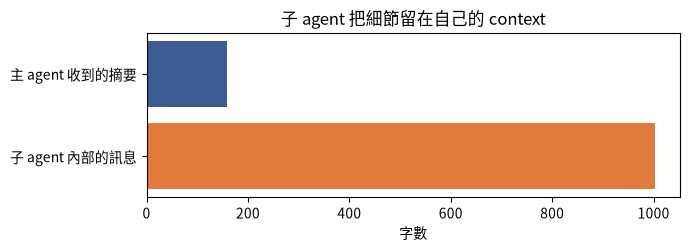

In [11]:
main_history = slim_agent.get_state(cfg).values["messages"]
sub_chars = sum(len(str(m.content)) for m in sub_events)
summary_chars = sum(len(str(m.content)) for m in main_history[start:] if type(m).__name__ == "ToolMessage")
print(f"子 agent 內部：{len(sub_events)} 則訊息、{sub_chars} 字")
print(f"主 agent 歷史新增：{len(main_history) - start} 則訊息，其中摘要 {summary_chars} 字")

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(["子 agent 內部的訊息", "主 agent 收到的摘要"], [sub_chars, summary_chars], color=["#e07b39", "#3b5b92"])
ax.set_xlabel("字數")
ax.set_title("子 agent 把細節留在自己的 context")
plt.tight_layout()
plt.show()

## Step 9：審批——`interrupt_on`

第三件：要求重啟。`restart_service` 列在 `interrupt_on` 裡，模型一呼叫，圖就停下來。

In [12]:
out = say("證據夠了，請呼叫 restart_service 重啟 order-db-proxy。")
pending = out["__interrupt__"][0].value
print(json.dumps(pending["action_requests"], ensure_ascii=False, indent=1))
print("允許的決定：", pending["review_configs"][0]["allowed_decisions"])
print("重啟過的服務（核准前）：", ot.restarted())

使用者：證據夠了，請呼叫 restart_service 重啟 order-db-proxy。
  AI     → restart_service({"service": "order-db-proxy"})
[
 {
  "name": "restart_service",
  "args": {
   "service": "order-db-proxy"
  },
  "description": "Tool execution requires approval\n\nTool: restart_service\nArgs: {'service': 'order-db-proxy'}"
 }
]
允許的決定： ['approve', 'edit', 'reject', 'respond']
重啟過的服務（核准前）： []


這跟 05 是同一個機制：底層是 `HumanInTheLoopMiddleware` 呼叫 LangGraph 的 `interrupt`。
核准用 `Command(resume={"decisions": [{"type": "approve"}]})`，也可以 `reject`、`edit`（改參數）或 `respond`。

In [13]:
from langgraph.types import Command

start = len(slim_agent.get_state(cfg).values["messages"])
out = slim_agent.invoke(Command(resume={"decisions": [{"type": "approve"}]}), cfg)
show_new(out, start - 1)
print("重啟過的服務（核准後）：", ot.restarted())

  AI     → restart_service({"service": "order-db-proxy"})
  Tool   ← '已重啟 order-db-proxy（第 1 次）'
  AI     ← '已重啟 order-db-proxy。請注意，這是第一次重啟，可能會有短暫的服務暫停。請密切監控 service 的狀態，並在必要時進行後續的排查。'
重啟過的服務（核准後）： ['order-db-proxy']


## Step 10：整段 thread 的工具呼叫

把主 agent 這個 thread 用過的工具依時間排出來：`read_file`（skill）、`task`（子 agent）、`restart_service`（審批後）。
這就是投影片 Lab5-C 那段 trace 的實際版本。

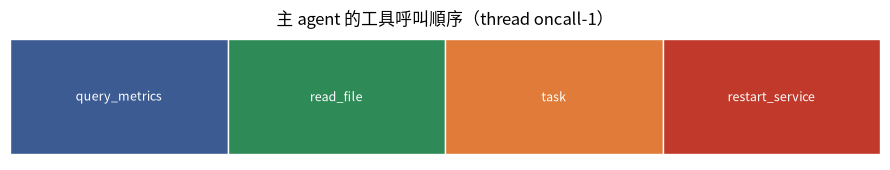

In [14]:
calls = [c["name"] for m in slim_agent.get_state(cfg).values["messages"] for c in (getattr(m, "tool_calls", None) or [])]
colors = {"read_file": "#2e8b57", "task": "#e07b39", "restart_service": "#c0392b"}
fig, ax = plt.subplots(figsize=(9, 1.8))
for i, name in enumerate(calls):
    ax.barh(0, 1, left=i, color=colors.get(name, "#3b5b92"), edgecolor="white")
    ax.text(i + 0.5, 0, name, ha="center", va="center", color="white", fontsize=9)
ax.set_xlim(0, max(1, len(calls)))
ax.axis("off")
ax.set_title("主 agent 的工具呼叫順序（thread oncall-1）")
plt.tight_layout()
plt.show()

## 試試看

1. 在 `workspace/skills/` 新增一個 skill（例如 `slow-query`：看到 `slow query` 就建議補索引），重跑 Step 5～6，確認 system prompt 自動多一行。
2. 在 Step 9 改送 `{"type": "reject", "message": "先不要重啟，等 DBA"}`，看模型怎麼回應。
3. 把 `excluded_tools` 裡的 `edit_file` 拿掉，請 agent「把『重啟後要查 error_rate』寫進 /AGENTS.md」，再打開 `workspace/AGENTS.md` 看看——這就是檔案記憶被更新。

## 小結

- `create_deep_agent` 一次組好 harness：記憶、skills、子 agent、壓縮、審批都是掛在同一個迴圈上的 middleware，底層是 LangGraph。
- 框架預設的 prompt 為大模型設計；接小模型要先看它送了什麼，再用 HarnessProfile 與 middleware 瘦身。
- 下一本 07 換 OpenAI Agents SDK，用同一個值班任務比較寫法。